Gráfico salvo em: C4_usuarios_vs_tempo_resposta.png


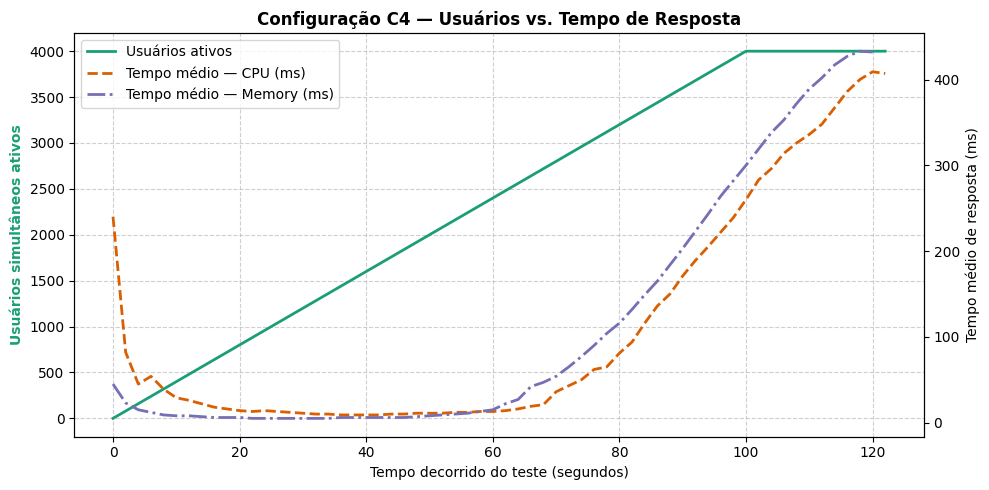

In [ ]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Escolher a configuração do experimento
configuracao = "C4"

# 2. Ler os logs das duas aplicações
dados = {}

for aplicacao in ["cpu", "memory"]:
    arquivo_log = f"{configuracao}/{configuracao}_{aplicacao}.log"
    dados_locust = []

    with open(arquivo_log, 'r') as f:
        conteudo_log = f.read().split("Response time percentiles")[0]

    for linha in conteudo_log.strip().split('\n'):
        if linha.strip().startswith('GET'):
            partes = [p for p in linha.strip().split() if p != '|']
            dados_locust.append({
                'media_ms': float(partes[4]),
                'mediana_ms': float(partes[7]),
            })

    df = pd.DataFrame(dados_locust)

    # 3. Calcular tempo decorrido e usuários ativos
    df['intervalo'] = range(len(df))
    df['tempo_decorrido_seg'] = df['intervalo'] * 2.0
    df['usuarios_ativos'] = np.minimum(
        4000, df['tempo_decorrido_seg'] * 40
    )

    dados[aplicacao] = df

# 4. Plotar usuários e tempos de resposta
fig, ax = plt.subplots(figsize=(10, 5))
ax_direito = ax.twinx()

cor1 = '#1b9e77'
cor2 = '#d95f02'
cor3 = '#7570b3'

linha1 = ax.plot(
    dados['cpu']['tempo_decorrido_seg'],
    dados['cpu']['usuarios_ativos'],
    color=cor1,
    linewidth=2,
    label='Usuários ativos'
)

linha2 = ax_direito.plot(
    dados['cpu']['tempo_decorrido_seg'],
    dados['cpu']['media_ms'],
    color=cor2,
    linewidth=2,
    linestyle='--',
    label='Tempo médio — CPU Bound (ms)'
)

linha3 = ax_direito.plot(
    dados['memory']['tempo_decorrido_seg'],
    dados['memory']['media_ms'],
    color=cor3,
    linewidth=2,
    linestyle='-.',
    label='Tempo médio — Memory Bound (ms)'
)

ax.set_title(
    f'Configuração {configuracao} — Usuários vs. Tempo de Resposta',
    fontsize=12,
    fontweight='bold'
)
ax.set_xlabel('Tempo decorrido do teste (segundos)')
ax.set_ylabel('Usuários simultâneos ativos', color=cor1, fontweight='bold')
ax_direito.set_ylabel('Tempo médio de resposta (ms)')

# Combinar as legendas
linhas = linha1 + linha2 + linha3
rotulos = [linha.get_label() for linha in linhas]
ax.legend(linhas, rotulos, loc='upper left')

ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# 5. Salvar o gráfico
arquivo_saida = f'{configuracao}_usuarios_vs_tempo_resposta.png'
plt.savefig(arquivo_saida, dpi=300)

print(f'Gráfico salvo em: {arquivo_saida}')
plt.show()


Gráfico salvo em: comparacao_cpu_C1_C2_C3_C4.png


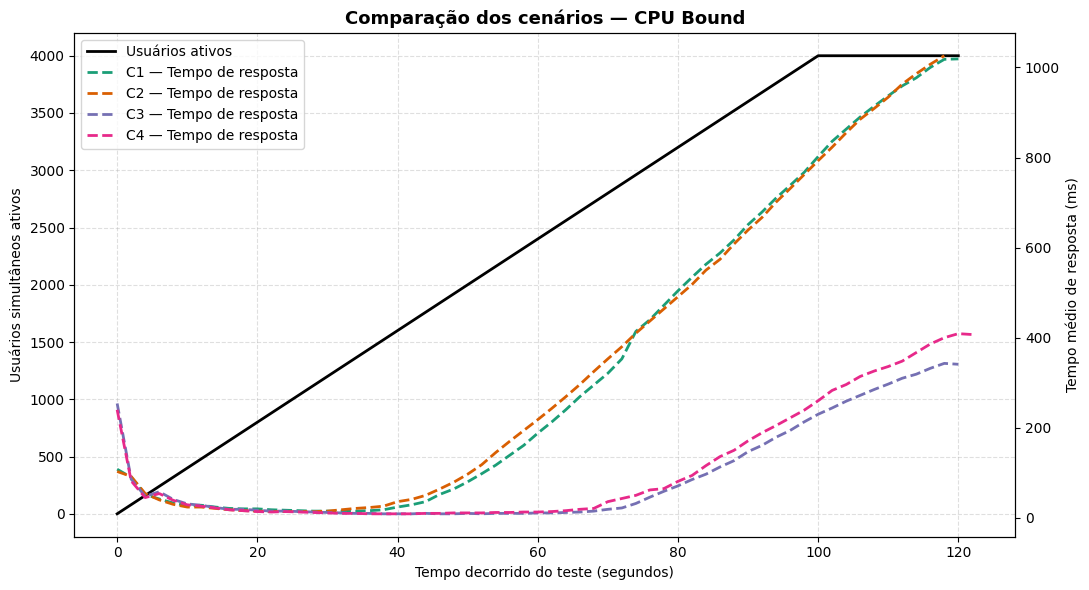

Gráfico salvo em: comparacao_memory_C1_C2_C3_C4.png


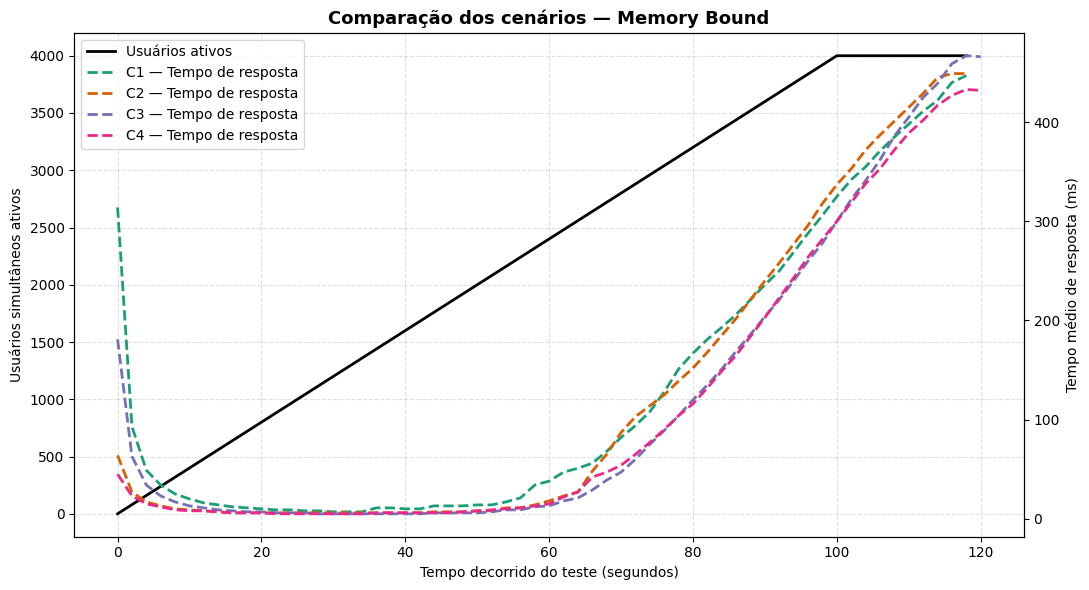

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Configurações do experimento
configuracoes = ["C1", "C2", "C3", "C4"]

aplicacoes = {
    "cpu": "CPU Bound",
    "memory": "Memory Bound"
}

# 2. Ler os logs das aplicações em todos os cenários
dados = {}

for aplicacao in aplicacoes:
    dados[aplicacao] = {}

    for configuracao in configuracoes:
        arquivo_log = f"{configuracao}/{configuracao}_{aplicacao}.log"
        dados_locust = []

        with open(arquivo_log, "r") as f:
            conteudo_log = f.read().split(
                "Response time percentiles"
            )[0]

        for linha in conteudo_log.strip().split("\n"):
            if linha.strip().startswith("GET"):
                partes = [
                    p for p in linha.strip().split() if p != "|"
                ]

                dados_locust.append({
                    "media_ms": float(partes[4]),
                    "mediana_ms": float(partes[7]),
                })

        df = pd.DataFrame(dados_locust)

        # 3. Calcular tempo decorrido e usuários ativos
        df["intervalo"] = range(len(df))
        df["tempo_decorrido_seg"] = df["intervalo"] * 2.0
        df["usuarios_ativos"] = np.minimum(
            4000, df["tempo_decorrido_seg"] * 40
        )

        dados[aplicacao][configuracao] = df

# 4. Cores dos cenários
cores = {
    "C1": "#1b9e77",
    "C2": "#d95f02",
    "C3": "#7570b3",
    "C4": "#e7298a"
}

# 5. Gerar um gráfico para cada aplicação
for aplicacao, nome_aplicacao in aplicacoes.items():

    fig, ax = plt.subplots(figsize=(11, 6))
    ax_direito = ax.twinx()

    # Usuários ativos: uma única curva compartilhada
    df_base = dados[aplicacao]["C1"]

    linha_usuarios, = ax.plot(
        df_base["tempo_decorrido_seg"],
        df_base["usuarios_ativos"],
        color="black",
        linewidth=2,
        label="Usuários ativos"
    )

    linhas = [linha_usuarios]

    # Tempo médio de resposta: uma curva por cenário
    for configuracao in configuracoes:
        df = dados[aplicacao][configuracao]

        linha, = ax_direito.plot(
            df["tempo_decorrido_seg"],
            df["media_ms"],
            color=cores[configuracao],
            linewidth=2,
            linestyle="--",
            label=f"{configuracao} — Tempo de resposta"
        )

        linhas.append(linha)

    # 6. Formatação do gráfico
    ax.set_title(
        f"Comparação dos cenários — {nome_aplicacao}",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Tempo decorrido do teste (segundos)")
    ax.set_ylabel("Usuários simultâneos ativos")
    ax_direito.set_ylabel("Tempo médio de resposta (ms)")

    ax.legend(
        linhas,
        [linha.get_label() for linha in linhas],
        loc="upper left"
    )

    ax.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()

    # 7. Salvar e exibir
    arquivo_saida = (
        f"comparacao_{aplicacao}_C1_C2_C3_C4.png"
    )

    plt.savefig(arquivo_saida, dpi=300)
    print(f"Gráfico salvo em: {arquivo_saida}")

    plt.show()

Gráfico salvo em: comparacao_cpu_util_pct_cpu.png


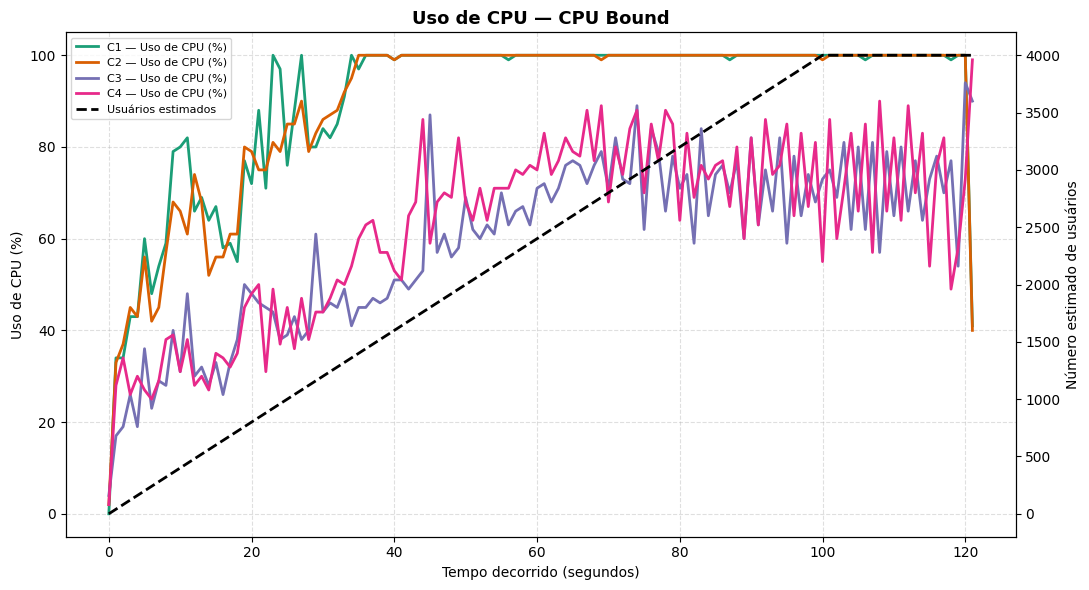

Gráfico salvo em: comparacao_memoria_usada_mb_cpu.png


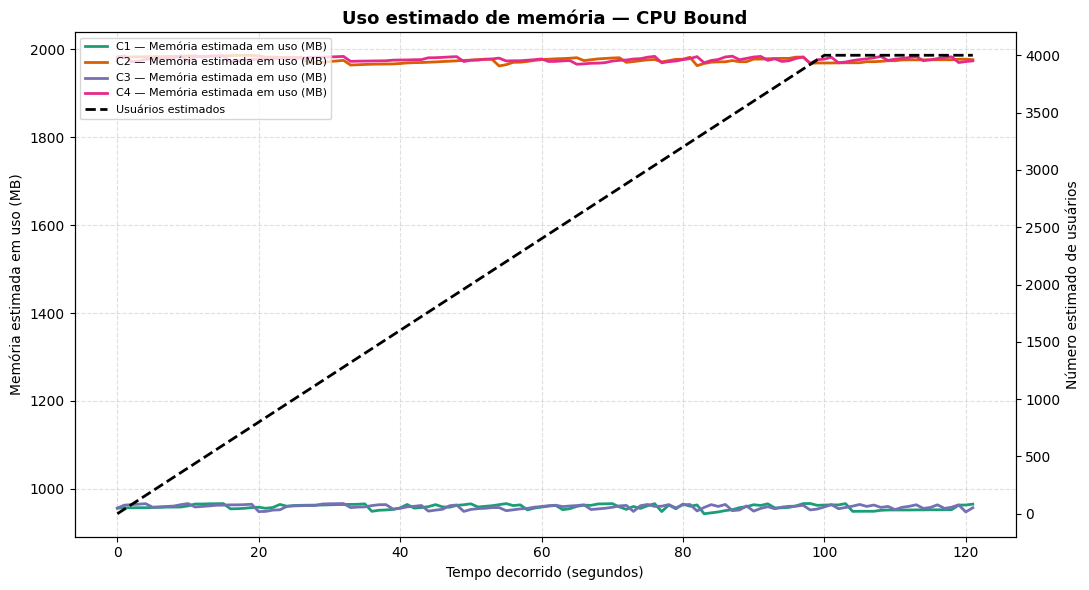

Gráfico salvo em: comparacao_cpu_util_pct_memory.png


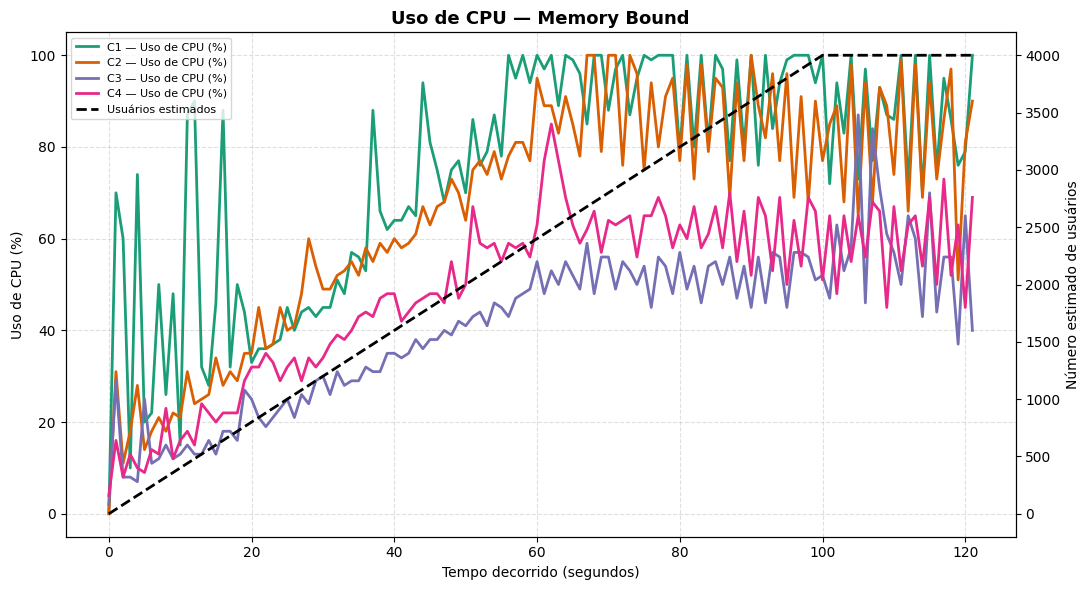

Gráfico salvo em: comparacao_memoria_usada_mb_memory.png


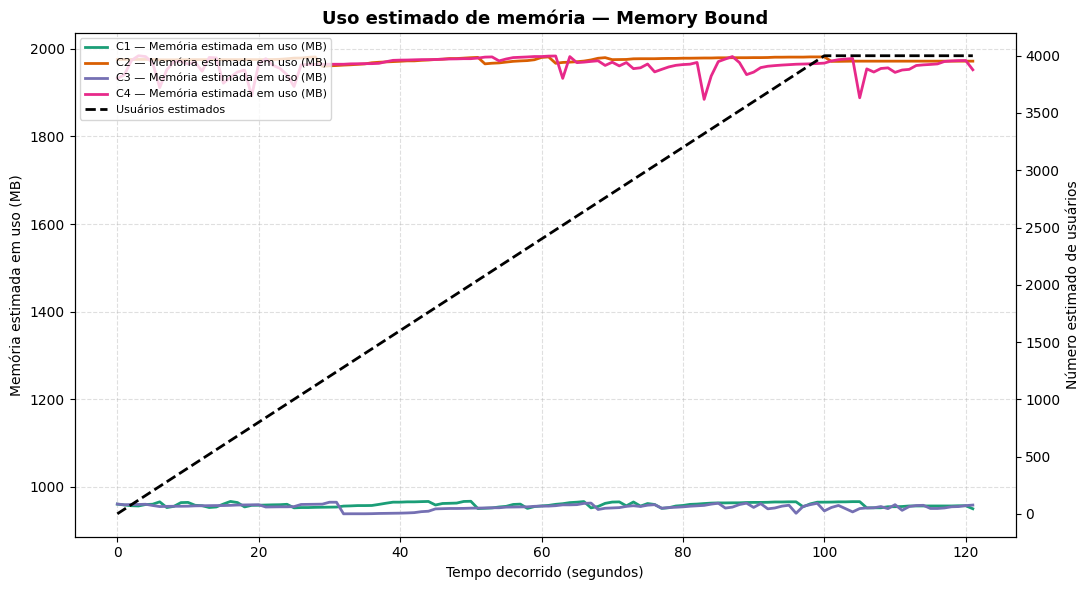

In [13]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configurações
configuracoes = ["C1", "C2", "C3", "C4"]
aplicacoes = {
    "cpu": "CPU Bound",
    "memory": "Memory Bound"
}

RAM_MB = {
    "C1": 1024,
    "C2": 2048,
    "C3": 1024,
    "C4": 2048
}

colunas = [
    "r", "b", "swpd", "free", "buff", "cache",
    "si", "so", "bi", "bo", "in", "cs",
    "us", "sy", "id", "wa", "st", "data", "hora"
]

# 2. Ler os dados
dados = {}

for aplicacao in aplicacoes:
    dados[aplicacao] = {}

    for configuracao in configuracoes:
        arquivo = (
            Path(configuracao)
            / f"{configuracao}_{aplicacao}_vmstat.txt"
        )

        linhas_validas = []

        with open(arquivo, "r") as f:
            for linha in f:
                valores = linha.split()

                if len(valores) != 19:
                    continue

                try:
                    [float(v) for v in valores[:17]]
                    linhas_validas.append(valores)
                except ValueError:
                    continue

        if len(linhas_validas) < 2:
            print(f"Dados insuficientes: {arquivo}")
            continue

        # Descartar a primeira amostra
        df = pd.DataFrame(
            linhas_validas,
            columns=colunas
        ).iloc[1:].copy()

        for coluna in colunas[:17]:
            df[coluna] = pd.to_numeric(
                df[coluna], errors="coerce"
            )

        # Tempo e métricas
        df["tempo_seg"] = range(len(df))
        df["cpu_util_pct"] = 100 - df["id"]

        df["memoria_usada_mb"] = (
            RAM_MB[configuracao] - df["free"] / 1024
        )

        # Perfil estimado de usuários:
        # aumento de 40 usuários por segundo, até 4000
        df["usuarios"] = (
            df["tempo_seg"] * 40
        ).clip(upper=4000)

        dados[aplicacao][configuracao] = df

# 3. Cores
cores = {
    "C1": "#1b9e77",
    "C2": "#d95f02",
    "C3": "#7570b3",
    "C4": "#e7298a"
}

# 4. Gerar os quatro gráficos
for aplicacao, nome_aplicacao in aplicacoes.items():

    for metrica, rotulo, titulo in [
        ("cpu_util_pct", "Uso de CPU (%)", "Uso de CPU"),
        (
            "memoria_usada_mb",
            "Memória estimada em uso (MB)",
            "Uso estimado de memória"
        )
    ]:
        fig, ax = plt.subplots(figsize=(11, 6))
        ax_direito = ax.twinx()

        linhas = []

        # Métrica de recurso para cada cenário
        for configuracao in configuracoes:
            if configuracao not in dados[aplicacao]:
                continue

            df = dados[aplicacao][configuracao]

            linha, = ax.plot(
                df["tempo_seg"],
                df[metrica],
                color=cores[configuracao],
                linewidth=2,
                label=f"{configuracao} — {rotulo}"
            )
            linhas.append(linha)

        # Usuários: desenhar uma única curva
        # pois o perfil de carga é igual nos cenários
        df_base = dados[aplicacao].get("C1")

        if df_base is not None:
            linha_usuarios, = ax_direito.plot(
                df_base["tempo_seg"],
                df_base["usuarios"],
                color="black",
                linestyle="--",
                linewidth=2,
                label="Usuários estimados"
            )
            linhas.append(linha_usuarios)

        ax.set_title(
            f"{titulo} — {nome_aplicacao}",
            fontsize=13,
            fontweight="bold"
        )

        ax.set_xlabel("Tempo decorrido (segundos)")
        ax.set_ylabel(rotulo)
        ax_direito.set_ylabel("Número estimado de usuários")

        ax.legend(
            linhas,
            [linha.get_label() for linha in linhas],
            loc="upper left",
            fontsize=8
        )

        ax.grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout()

        arquivo_saida = (
            f"comparacao_{metrica}_{aplicacao}.png"
        )
        plt.savefig(arquivo_saida, dpi=300)
        print(f"Gráfico salvo em: {arquivo_saida}")

        plt.show()
